# 2. Thống kê và khám phá dữ liệu (EDA)

Không cần phần trước.

Muốn chạy toàn bộ trong một kernel: [mở notebook 00](00_Gamer_Behavior_Clustering.ipynb).

<details><summary>Danh sách tám phần</summary>

- [1. Tìm hiểu bài toán và dữ liệu](01_data_understanding.ipynb)

- [2. Thống kê và khám phá dữ liệu (EDA)](02_statistics_eda.ipynb)

- [3. Kiểm tra và làm sạch dữ liệu](03_data_cleaning.ipynb)

- [4. Chia dữ liệu và chuẩn hóa](04_data_transformation.ipynb)

- [5. Ward, K-Means và cách kết hợp](05_clustering.ipynb)

- [6. Đánh giá holdout và độ nhạy](06_model_evaluation.ipynb)

- [7. Hồ sơ người chơi và trực quan hóa](07_player_profiling.ipynb)

- [8. Gán người chơi và đề xuất chiến lược](08_prediction_strategy.ipynb)

</details>

## Khởi tạo và đọc dữ liệu

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown

# Tìm gốc dự án khi mở từ thư mục notebooks/, gamer_profiling/ hoặc workspace.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "gamer_profiling"]
ROOT = next((p for p in candidates if (p / "gamer_clustering.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án gamer_profiling hoặc notebooks/.")
NBOUT = Path(os.environ.get("GAMER_NOTEBOOK_OUTPUT", str(ROOT / "outputs/notebook/latest")))
NBOUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(NBOUT / ".matplotlib"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from gamer_clustering import clean_features, centers_from_labels, metrics, choose_k
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (pairwise_distances, silhouette_score, silhouette_samples,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.metrics.pairwise import pairwise_distances_argmin
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import seaborn as sns

# Module .py dùng Agg khi chạy batch; trong notebook cần hiển thị hình ngay dưới ô code.
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid", font="DejaVu Sans", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
SEED = 42
FEATURES = ["PlayTimeHours", "SessionsPerWeek", "AvgSessionDurationMinutes",
            "PlayerLevel", "AchievementsUnlocked"]
METHODS = ["KMeans", "Ward", "Ward_KMeans"]
SOURCE = ROOT / "data/online_gaming_behavior_dataset.csv"
df = pd.read_csv(SOURCE)
reference = json.loads((ROOT / "outputs/summary.json").read_text(encoding="utf-8"))

def require(name, previous):
    path = NBOUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {name}. Chạy notebook {previous} trước, hoặc Run All notebook 00.")
    return path

def save_plot(name):
    plt.tight_layout()
    plt.savefig(NBOUT / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

EDA trả lời: dữ liệu phân bố thế nào, có thiếu hoặc trùng không, các biến có tương quan không?
Các thống kê toàn bộ dữ liệu ở phần này phục vụ mô tả. Bộ điền thiếu, scaler và việc chọn k ở phần sau
chỉ học trên train. Boxplot đánh dấu giá trị xa phần giữa phân phối; đó chưa phải lý do để xóa người chơi.

In [2]:
display(df[FEATURES].describe().T)
display(pd.DataFrame({"dtype": df.dtypes.astype(str),
                      "missing": df.isna().sum(), "unique": df.nunique()}))
print("Dòng trùng:", df.duplicated().sum(), "| ID trùng:", df.PlayerID.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
PlayTimeHours,40034.0,12.0244,6.9146,0.0001,6.0675,12.008,17.9638,23.9996
SessionsPerWeek,40034.0,9.4718,5.7637,0.0000,4.0000,9.000,14.0000,19.0000
AvgSessionDurationMinutes,40034.0,94.7923,49.0114,10.0000,52.0000,95.000,137.0000,179.0000
PlayerLevel,40034.0,49.6556,28.5884,1.0000,25.0000,49.000,74.0000,99.0000
AchievementsUnlocked,40034.0,24.5265,14.4307,0.0000,12.0000,25.000,37.0000,49.0000


,dtype,missing,unique
PlayerID,int64,0,40034
Age,int64,0,35
Gender,str,0,2
Location,str,0,4
GameGenre,str,0,5
PlayTimeHours,float64,0,40034
InGamePurchases,int64,0,2
GameDifficulty,str,0,3
SessionsPerWeek,int64,0,20
AvgSessionDurationMinutes,int64,0,170


Dòng trùng: 0 | ID trùng: 0


Histogram biểu diễn số người theo từng khoảng giá trị. Phân phối gần đều không tự chứng minh có các nhóm tự nhiên.

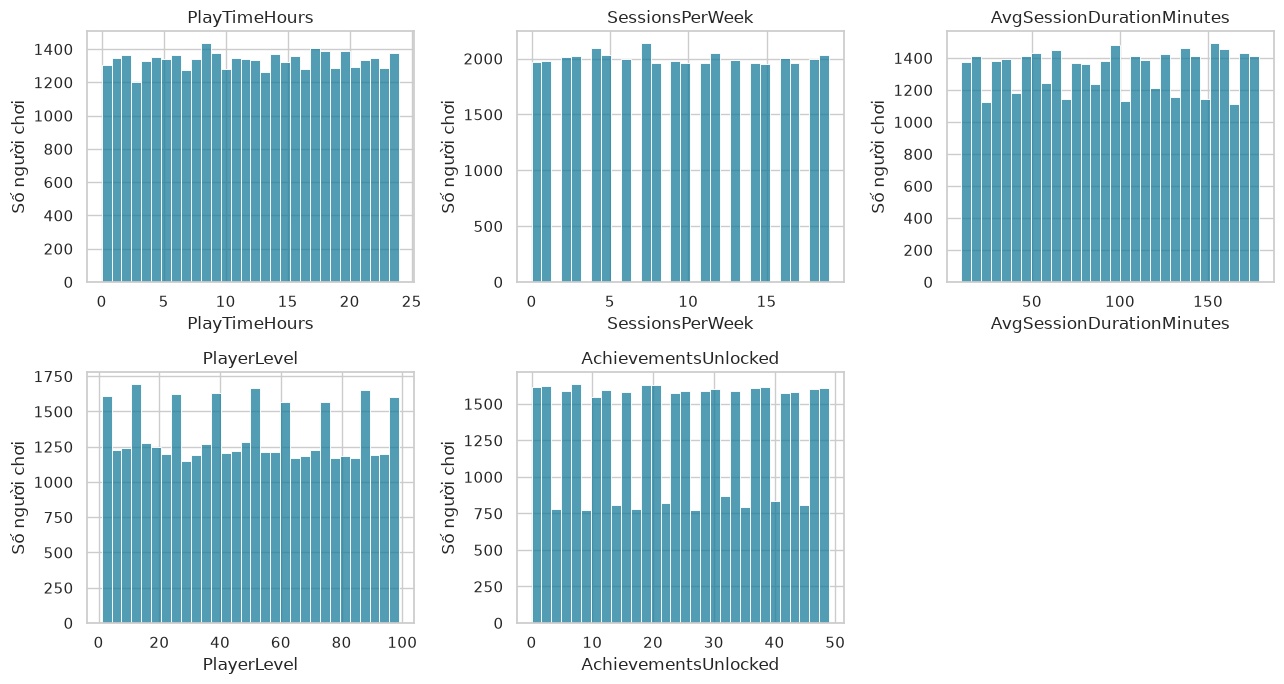

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(df[col], bins=30, color="#197c9b", ax=ax)
    ax.set_title(col); ax.set_ylabel("Số người chơi")
axes.flat[-1].axis("off")
save_plot("02_histograms.png")

Boxplot: đường giữa hộp là trung vị; hộp chứa khoảng 50% dữ liệu ở giữa.
Điểm ngoài râu theo quy tắc IQR là giá trị xa phân phối, cần kiểm tra nghiệp vụ trước khi xử lý.

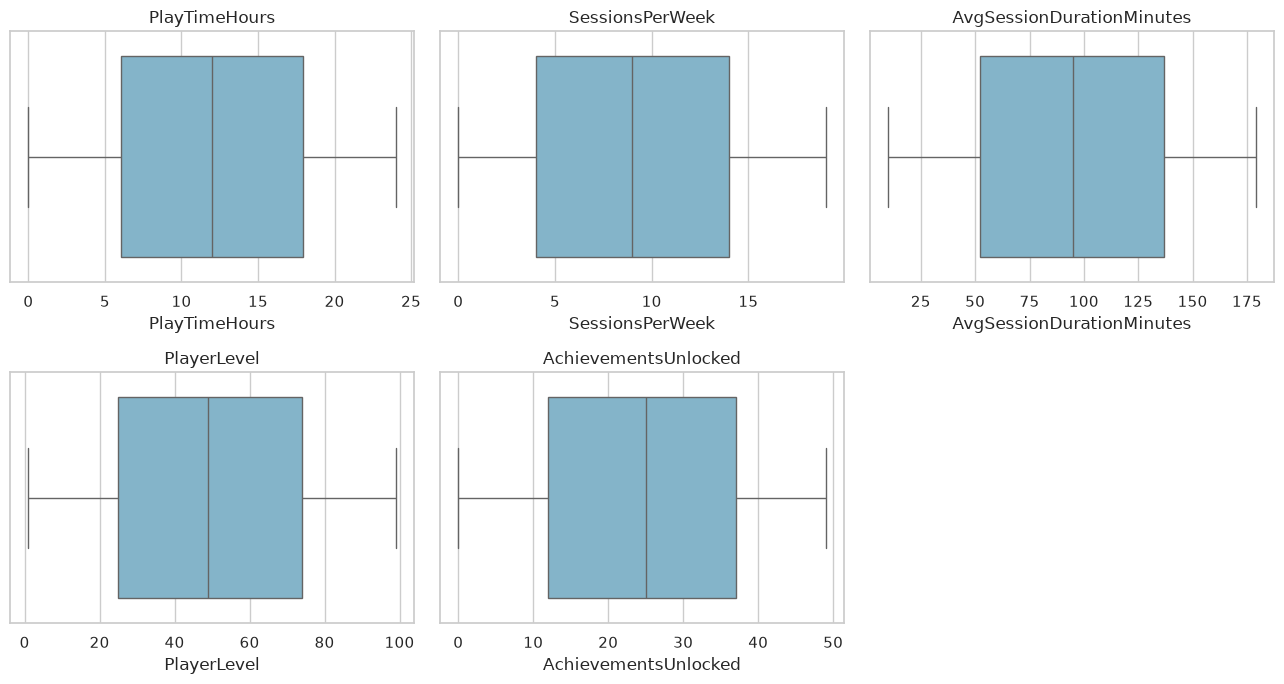

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(x=df[col], ax=ax, color="#79b8d4")
    ax.set_title(col)
axes.flat[-1].axis("off")
save_plot("02_boxplots.png")

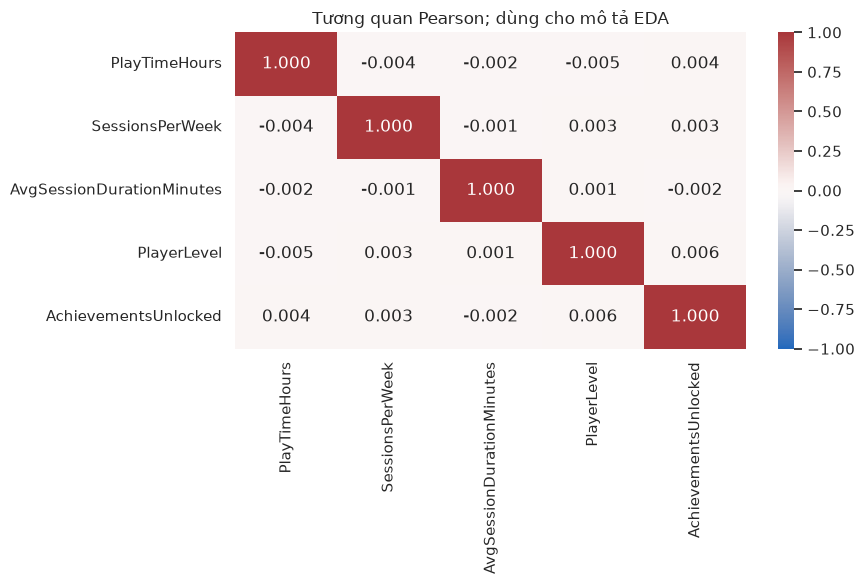

,Kiểm tra,Giá trị
0,"Lệch hai thời lượng quá 0,1 giờ",0.9925
1,Tương quan hai cột,-0.0019


Có **99.25%** dòng không khớp nếu đổi phút sang giờ. Không tự diễn giải PlayTimeHours là giờ/tuần. Sẽ kiểm tra độ nhạy khi bỏ cột này.

In [5]:
plt.figure(figsize=(9, 6))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Tương quan Pearson; dùng cho mô tả EDA")
save_plot("02_correlations.png")

disagreement = (df.PlayTimeHours - df.AvgSessionDurationMinutes / 60).abs() > 0.1
display(pd.DataFrame({"Kiểm tra": ["Lệch hai thời lượng quá 0,1 giờ", "Tương quan hai cột"],
                      "Giá trị": [disagreement.mean(), df.PlayTimeHours.corr(df.AvgSessionDurationMinutes)]}))
display(Markdown(f"Có **{disagreement.mean():.2%}** dòng không khớp nếu đổi phút sang giờ. "
                 "Không tự diễn giải PlayTimeHours là giờ/tuần. Sẽ kiểm tra độ nhạy khi bỏ cột này."))